In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("nepal_tourism_reviews.csv")

df.head()

,city,domain,place,rating,label,review,llama_label,llama_p_neg,llama_p_neu,llama_p_pos,qwen_label,qwen_p_neg,qwen_p_neu,qwen_p_pos
0,Pokhara,Attraction,Devi's Fall,1,negative,We visited Devi's Falls and honestly regretted...,negative,0.998249,0.001741,0.000010,negative,9.989350e-01,0.001065,2.234311e-11
1,Pokhara,Attraction,Devi's Fall,2,negative,"VisitorsVisitors pay a small fee, then enter t...",neutral,0.030214,0.969753,0.000033,neutral,1.770427e-07,1.000000,1.279035e-13
2,Pokhara,Attraction,Devi's Fall,3,neutral,The waterfall is in the middle of the town. Th...,neutral,0.003068,0.688856,0.308076,positive,9.307695e-10,0.392337,6.076632e-01
3,Pokhara,Attraction,Devi's Fall,1,negative,overrated. nothing much about the devi's fall....,negative,0.998963,0.001024,0.000013,negative,9.998766e-01,0.000123,2.713082e-12
4,Pokhara,Attraction,Devi's Fall,1,negative,Nothing here to see that is memorable. This is...,negative,0.998562,0.001356,0.000082,negative,9.995345e-01,0.000466,1.988430e-11


In [3]:
print("Dataset shape:", df.shape)

Dataset shape: (10536, 14)


In [4]:
# Display information about the dataset
df.info()
# Check missing values in each column
df.isnull().sum()
# Check duplicate rows
df.duplicated().sum()
# Count the number of reviews in each sentiment category
df["label"].value_counts()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10536 entries, 0 to 10535
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   city         10536 non-null  object 
 1   domain       10536 non-null  object 
 2   place        10536 non-null  object 
 3   rating       10536 non-null  int64  
 4   label        10536 non-null  object 
 5   review       10536 non-null  object 
 6   llama_label  10536 non-null  object 
 7   llama_p_neg  10536 non-null  float64
 8   llama_p_neu  10536 non-null  float64
 9   llama_p_pos  10536 non-null  float64
 10  qwen_label   10536 non-null  object 
 11  qwen_p_neg   10536 non-null  float64
 12  qwen_p_neu   10536 non-null  float64
 13  qwen_p_pos   10536 non-null  float64
dtypes: float64(6), int64(1), object(7)
memory usage: 1.1+ MB


label
positive    6274
neutral     2899
negative    1363
Name: count, dtype: int64

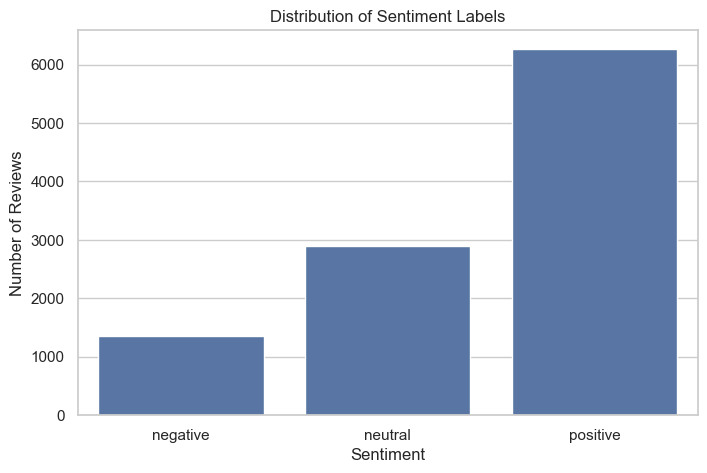

In [5]:
#Exploratory Data Analysis
# Visualize the distribution of sentiment labels

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="label",
    order=["negative", "neutral", "positive"]
)

plt.title("Distribution of Sentiment Labels")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [6]:
# Calculate the number of words in each review

df["word_count"] = df["review"].str.split().str.len()

# Calculate average review length

print("Average review length:", df["word_count"].mean())

# Display the first five reviews with their word counts

df[["review", "word_count"]].head()

Average review length: 69.35905466970387


,review,word_count
0,We visited Devi's Falls and honestly regretted...,80
1,"VisitorsVisitors pay a small fee, then enter t...",76
2,The waterfall is in the middle of the town. Th...,60
3,overrated. nothing much about the devi's fall....,30
4,Nothing here to see that is memorable. This is...,32


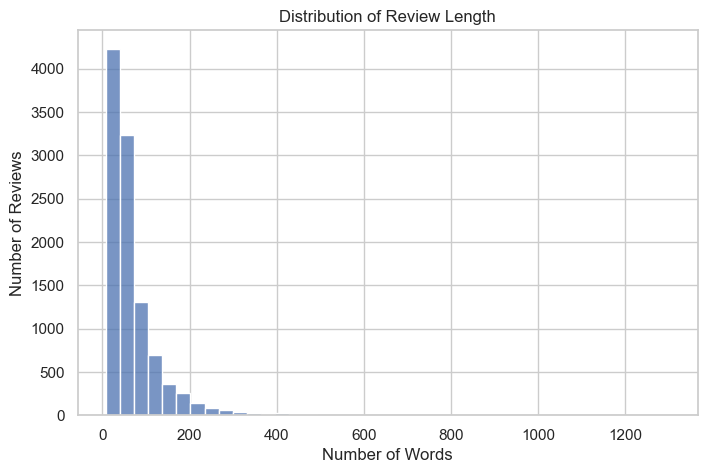

In [7]:
# Visualize the distribution of review lengths

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="word_count",
    bins=40
)

plt.title("Distribution of Review Length")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")

plt.show()

In [8]:
# Count sentiment categories for each city

city_sentiment = pd.crosstab(
    df["city"],
    df["label"]
)

display(city_sentiment)

label,negative,neutral,positive
city,,,
Kathmandu,874,1743,3275
Pokhara,489,1156,2999


In [9]:
# Calculate sentiment percentages for each city

city_sentiment_percent = pd.crosstab(
    df["city"],
    df["label"],
    normalize="index"
) * 100

display(city_sentiment_percent.round(2))

label,negative,neutral,positive
city,,,
Kathmandu,14.83,29.58,55.58
Pokhara,10.53,24.89,64.58


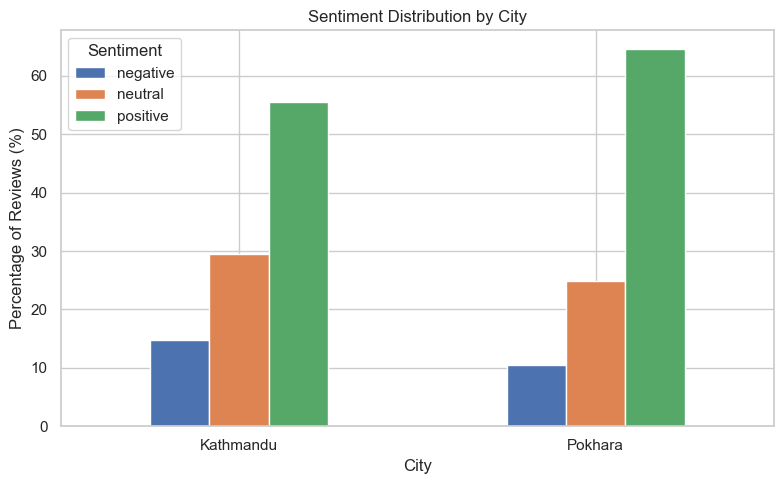

In [10]:
# Visualize sentiment percentages by city

city_sentiment_percent.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Sentiment Distribution by City")
plt.xlabel("City")
plt.ylabel("Percentage of Reviews (%)")

plt.xticks(rotation=0)
plt.legend(title="Sentiment")

plt.tight_layout()
plt.show()

In [11]:
# Calculate sentiment percentages by tourism domain

domain_sentiment = pd.crosstab(
    df["domain"],
    df["label"],
    normalize="index"
) * 100

display(domain_sentiment.round(2))

label,negative,neutral,positive
domain,,,
Attraction,9.09,26.40,64.52
Hotel,18.34,29.08,52.58


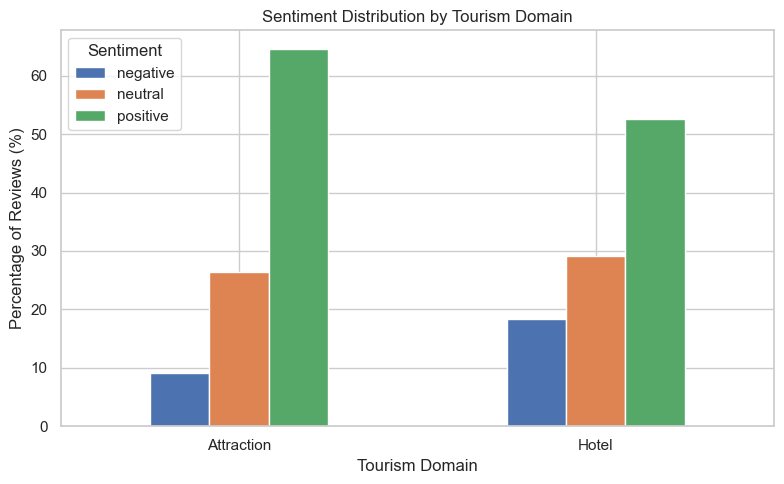

In [12]:
# Visualize sentiment by tourism domain

domain_sentiment.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Sentiment Distribution by Tourism Domain")
plt.xlabel("Tourism Domain")
plt.ylabel("Percentage of Reviews (%)")

plt.xticks(rotation=0)
plt.legend(title="Sentiment")

plt.tight_layout()
plt.show()

In [13]:
# Count the number of reviews for each rating

rating_counts = df["rating"].value_counts().sort_index()

display(rating_counts)

rating
1     606
2     757
3    2899
4    1661
5    4613
Name: count, dtype: int64

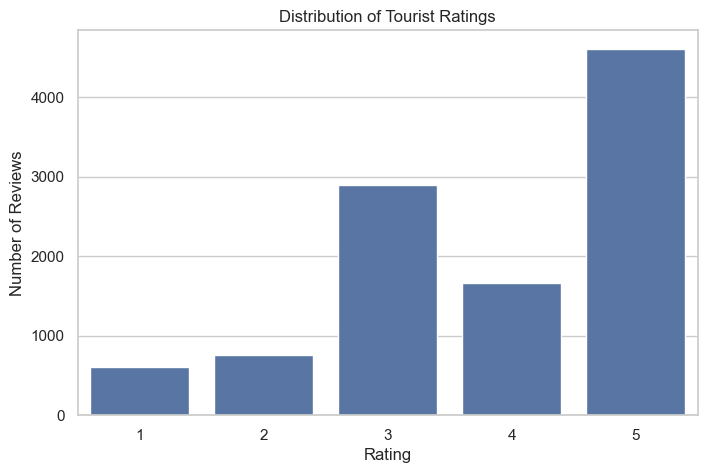

In [14]:
# Visualize rating distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="rating",
    order=[1, 2, 3, 4, 5]
)

plt.title("Distribution of Tourist Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")

plt.show()

In [15]:
# Select the review and sentiment columns
df = df[["review", "label"]].copy()

# Remove missing values and duplicate records
df = df.dropna()
df = df.drop_duplicates()

# Separate input and target
X = df["review"]
y = df["label"]

print("Dataset shape:", df.shape)
print("\nSentiment distribution:")
print(y.value_counts())

Dataset shape: (10536, 2)

Sentiment distribution:
label
positive    6274
neutral     2899
negative    1363
Name: count, dtype: int64


In [16]:
#Split the dataset
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 8428
Testing samples: 2108


In [17]:
#convert text into numerical features using TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

Training data shape: (8428, 5000)
Testing data shape: (2108, 5000)


In [18]:
# Train two machine learning models
# Model-1:Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train_tfidf, y_train)

# Make predictions
lr_predictions = lr_model.predict(X_test_tfidf)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [19]:
# Model-2:Linear Support Vector Machine(SVM)
from sklearn.svm import LinearSVC

# Create Linear SVM model
svm_model = LinearSVC(random_state=42)

# Train the model
svm_model.fit(X_train_tfidf, y_train)

# Make predictions
svm_predictions = svm_model.predict(X_test_tfidf)

print("Linear SVM model trained successfully!")

Linear SVM model trained successfully!


In [20]:
#Evaluate the Models
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Evaluate Logistic Regression
lr_accuracy = accuracy_score(y_test, lr_predictions)
lr_precision = precision_score(y_test, lr_predictions, average="weighted")
lr_recall = recall_score(y_test, lr_predictions, average="weighted")
lr_f1 = f1_score(y_test, lr_predictions, average="weighted")

# Evaluate Linear SVM
svm_accuracy = accuracy_score(y_test, svm_predictions)
svm_precision = precision_score(y_test, svm_predictions, average="weighted")
svm_recall = recall_score(y_test, svm_predictions, average="weighted")
svm_f1 = f1_score(y_test, svm_predictions, average="weighted")

print("Logistic Regression")
print("Accuracy:", lr_accuracy)
print("Precision:", lr_precision)
print("Recall:", lr_recall)
print("F1-score:", lr_f1)

print("\nLinear SVM")
print("Accuracy:", svm_accuracy)
print("Precision:", svm_precision)
print("Recall:", svm_recall)
print("F1-score:", svm_f1)

Logistic Regression
Accuracy: 0.7623339658444023
Precision: 0.7528830397922955
Recall: 0.7623339658444023
F1-score: 0.7501411437314457

Linear SVM
Accuracy: 0.7471537001897534
Precision: 0.7371610572371459
Recall: 0.7471537001897534
F1-score: 0.7401702044016086


In [21]:
#Creating a model comparison table
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Linear SVM"],
    "Accuracy": [lr_accuracy, svm_accuracy],
    "Precision": [lr_precision, svm_precision],
    "Recall": [lr_recall, svm_recall],
    "F1-Score": [lr_f1, svm_f1]
})

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.7623,0.7529,0.7623,0.7501
1,Linear SVM,0.7472,0.7372,0.7472,0.7402


In [22]:
#Classification Report
print("LOGISTIC REGRESSION")
print(classification_report(y_test, lr_predictions))

print("\nLINEAR SVM")
print(classification_report(y_test, svm_predictions))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

    negative       0.74      0.44      0.55       273
     neutral       0.63      0.56      0.59       580
    positive       0.81      0.93      0.87      1255

    accuracy                           0.76      2108
   macro avg       0.73      0.64      0.67      2108
weighted avg       0.75      0.76      0.75      2108


LINEAR SVM
              precision    recall  f1-score   support

    negative       0.65      0.52      0.58       273
     neutral       0.59      0.54      0.56       580
    positive       0.82      0.89      0.86      1255

    accuracy                           0.75      2108
   macro avg       0.69      0.65      0.67      2108
weighted avg       0.74      0.75      0.74      2108



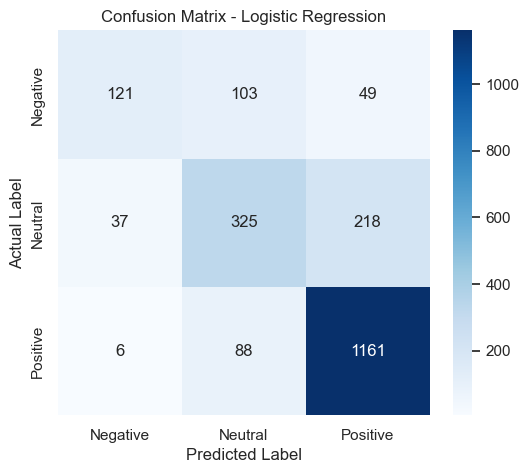

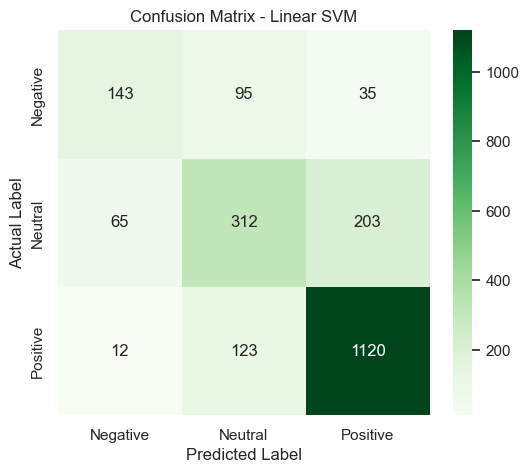

In [23]:
#Confusion Matrix

# Logistic Regression Confusion Matrix
lr_cm = confusion_matrix(
    y_test, lr_predictions,
    labels=["negative", "neutral", "positive"]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    lr_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()


# Linear SVM Confusion Matrix
svm_cm = confusion_matrix(
    y_test, svm_predictions,
    labels=["negative", "neutral", "positive"]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    svm_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)
plt.title("Confusion Matrix - Linear SVM")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [24]:
#Hyperparameter Tuning


# Logistic Regression tuning
lr_parameters = {
    "C": [0.1, 1, 10, 100]
}

lr_grid = GridSearchCV(
    LogisticRegression(max_iter=1000),
    lr_parameters,
    cv=3,
    scoring="f1_macro",
    n_jobs=-1
)

lr_grid.fit(X_train_tfidf, y_train)

print("Best Logistic Regression Parameters:", lr_grid.best_params_)
print("Best Logistic Regression CV F1-score:", lr_grid.best_score_)

Best Logistic Regression Parameters: {'C': 10}
Best Logistic Regression CV F1-score: 0.6541532414523585


In [25]:
# Linear SVM tuning

svm_parameters = {
    "C": [0.1, 1, 10, 100]
}

svm_grid = GridSearchCV(
    LinearSVC(random_state=42),
    svm_parameters,
    cv=3,
    scoring="f1_macro",
    n_jobs=-1
)

svm_grid.fit(X_train_tfidf, y_train)

print("Best Linear SVM Parameters:", svm_grid.best_params_)
print("Best Linear SVM CV F1-score:", svm_grid.best_score_)

Best Linear SVM Parameters: {'C': 1}
Best Linear SVM CV F1-score: 0.6547601852641601


In [26]:
# Evaluate the tuned models
# Get the best tuned models
best_lr_model = lr_grid.best_estimator_
best_svm_model = svm_grid.best_estimator_

# Make predictions
best_lr_predictions = best_lr_model.predict(X_test_tfidf)
best_svm_predictions = best_svm_model.predict(X_test_tfidf)

# Calculate test performance
print("TUNED LOGISTIC REGRESSION")
print(classification_report(y_test, best_lr_predictions))

print("\nTUNED LINEAR SVM")
print(classification_report(y_test, best_svm_predictions))

TUNED LOGISTIC REGRESSION
              precision    recall  f1-score   support

    negative       0.64      0.52      0.57       273
     neutral       0.58      0.56      0.57       580
    positive       0.84      0.89      0.86      1255

    accuracy                           0.75      2108
   macro avg       0.69      0.66      0.67      2108
weighted avg       0.74      0.75      0.74      2108


TUNED LINEAR SVM
              precision    recall  f1-score   support

    negative       0.65      0.52      0.58       273
     neutral       0.59      0.54      0.56       580
    positive       0.82      0.89      0.86      1255

    accuracy                           0.75      2108
   macro avg       0.69      0.65      0.67      2108
weighted avg       0.74      0.75      0.74      2108



In [27]:
#Creating the final model comparison table
final_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression (Original)",
        "Linear SVM (Original)",
        "Logistic Regression (Tuned)",
        "Linear SVM (Tuned)"
    ],
    "Accuracy": [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, svm_predictions),
        accuracy_score(y_test, best_lr_predictions),
        accuracy_score(y_test, best_svm_predictions)
    ],
    "Macro F1-Score": [
        f1_score(y_test, lr_predictions, average="macro"),
        f1_score(y_test, svm_predictions, average="macro"),
        f1_score(y_test, best_lr_predictions, average="macro"),
        f1_score(y_test, best_svm_predictions, average="macro")
    ],
    "Weighted F1-Score": [
        f1_score(y_test, lr_predictions, average="weighted"),
        f1_score(y_test, svm_predictions, average="weighted"),
        f1_score(y_test, best_lr_predictions, average="weighted"),
        f1_score(y_test, best_svm_predictions, average="weighted")
    ]
})

display(final_comparison.round(4))

,Model,Accuracy,Macro F1-Score,Weighted F1-Score
0,Logistic Regression (Original),0.7623,0.6708,0.7501
1,Linear SVM (Original),0.7472,0.6665,0.7402
2,Logistic Regression (Tuned),0.7486,0.6682,0.7438
3,Linear SVM (Tuned),0.7472,0.6665,0.7402


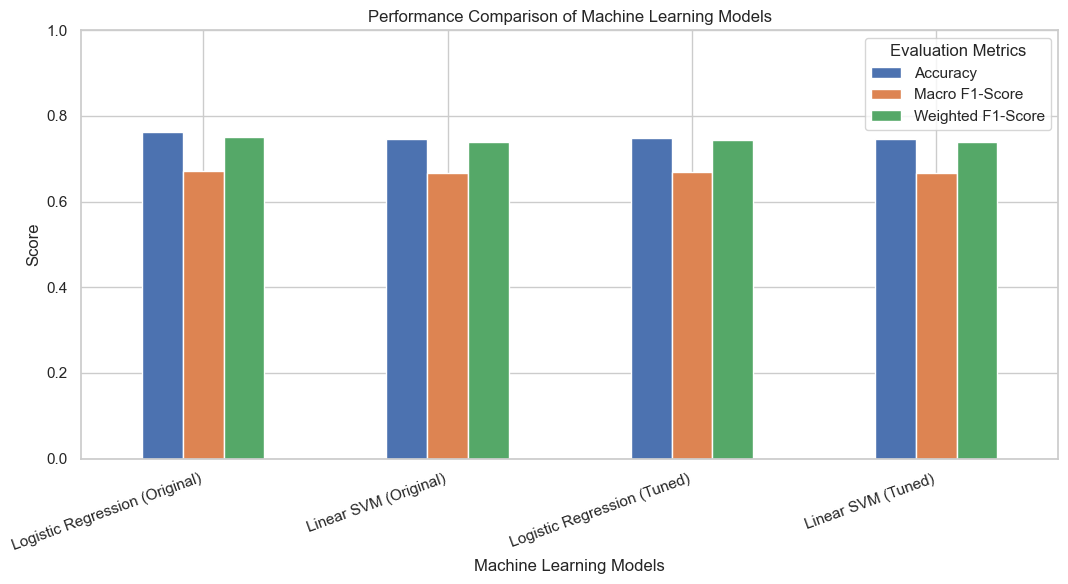

In [28]:
# Model Performance Comparison graph
final_comparison.set_index("Model")[
    ["Accuracy", "Macro F1-Score", "Weighted F1-Score"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Performance Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(title="Evaluation Metrics")
plt.tight_layout()
plt.show()


In [29]:
# Test the model with new tourist reviews

sample_reviews = [
    "The hotel was amazing and the staff were very friendly.",
    "The experience was average and nothing special.",
    "The service was terrible and the room was dirty."
]

# Convert reviews using the existing TF-IDF vectorizer
sample_tfidf = tfidf.transform(sample_reviews)

# Predict sentiment
sample_predictions = lr_model.predict(sample_tfidf)

# Display results
for review, prediction in zip(sample_reviews, sample_predictions):
    print("Review:", review)
    print("Predicted Sentiment:", prediction)
    print()

Review: The hotel was amazing and the staff were very friendly.
Predicted Sentiment: positive

Review: The experience was average and nothing special.
Predicted Sentiment: neutral

Review: The service was terrible and the room was dirty.
Predicted Sentiment: negative



In [30]:
import joblib

# Save the best model and TF-IDF vectorizer
joblib.dump(lr_model, "tourism_sentiment_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and TF-IDF vectorizer saved successfully!")

Model and TF-IDF vectorizer saved successfully!
